Dataset for loan prediction is given

In [83]:
# 1. Load the dataset in Python environment

import pandas as pd
import seaborn as sns

train = pd.read_csv("/content/train_loan.csv")
train

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


In [84]:
tr = train.drop('Loan_ID', axis=1)
tr

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...
609,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


In [85]:
tr.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Gender             601 non-null    object 
 1   Married            611 non-null    object 
 2   Dependents         599 non-null    object 
 3   Education          614 non-null    object 
 4   Self_Employed      582 non-null    object 
 5   ApplicantIncome    614 non-null    int64  
 6   CoapplicantIncome  614 non-null    float64
 7   LoanAmount         592 non-null    float64
 8   Loan_Amount_Term   600 non-null    float64
 9   Credit_History     564 non-null    float64
 10  Property_Area      614 non-null    object 
 11  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(7)
memory usage: 57.7+ KB


In [86]:
tr.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [87]:
tr.duplicated().sum()

np.int64(0)

In [88]:
tr.isnull().sum()

,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14
Credit_History,50


In [89]:
tr["Dependents"] = tr["Dependents"].replace("3+", "3")
tr.value_counts("Dependents")


,count
Dependents,
0,345
1,102
2,101
3,51


a. MISSING VALUE HANDLING

Fill all catagorical columns with MODE and numerical columns with MEDIAN

In [90]:
cat_cols = tr.select_dtypes(include="object").columns
cat_cols

Index(['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed',
       'Property_Area', 'Loan_Status'],
      dtype='object')

In [91]:
num_cols = tr.select_dtypes(include="number").columns
num_cols

Index(['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History'],
      dtype='object')

In [92]:
from sklearn.impute import SimpleImputer
num_cols = tr.select_dtypes(include="number").columns
imputer_num = SimpleImputer(strategy="median")
tr[num_cols] = imputer_num.fit_transform(tr[num_cols])

cat_cols = tr.select_dtypes(include="object").columns
imputer_cat = SimpleImputer(strategy="most_frequent")
tr[cat_cols] = imputer_cat.fit_transform(tr[cat_cols])

In [93]:
tr[num_cols].isnull().sum()

,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,0
Credit_History,0


In [94]:
tr[cat_cols].isnull().sum()

,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
Property_Area,0
Loan_Status,0


b. OUTLIER DETECTION


In [95]:
tr.isna().sum()

,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,0
Credit_History,0


<Axes: >

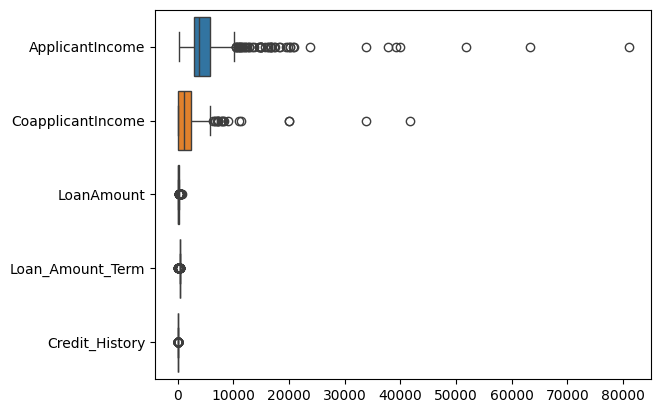

In [96]:

sns.boxplot(data=tr[num_cols], orient="h")

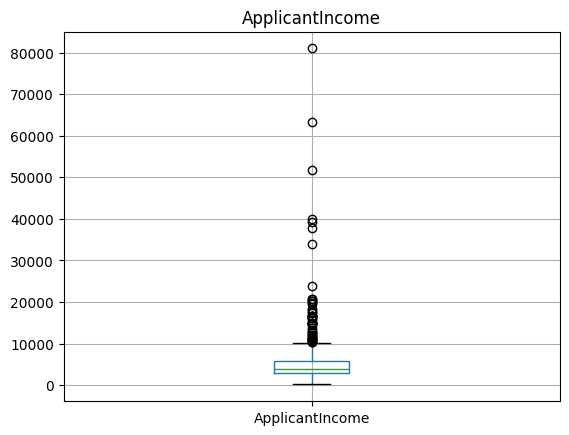

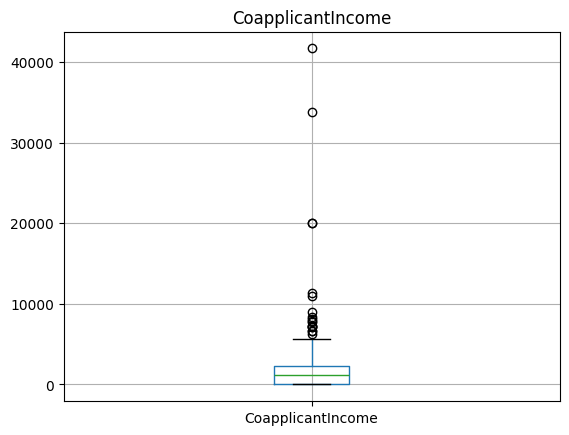

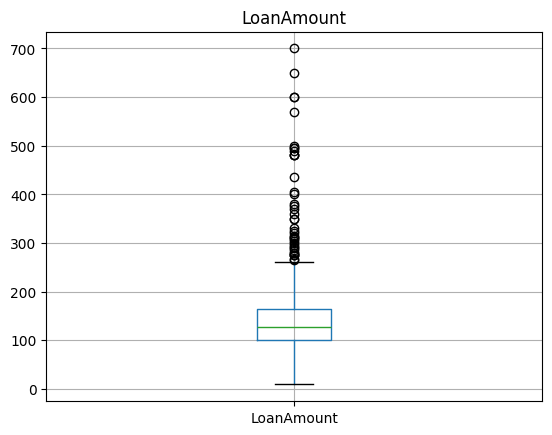

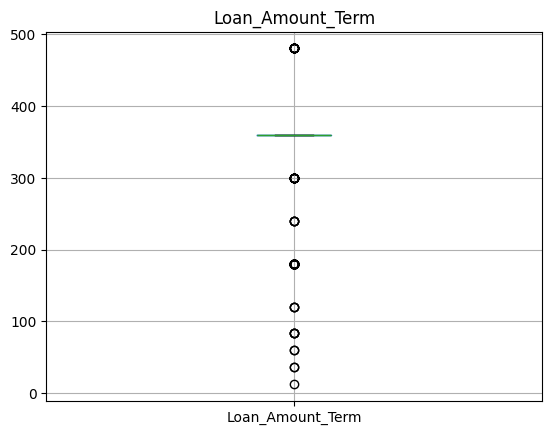

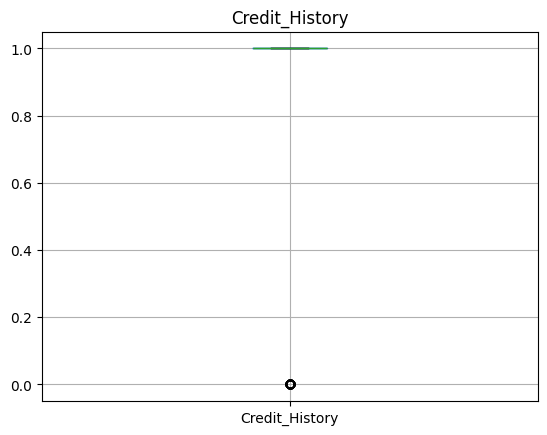

In [97]:
import matplotlib.pyplot as plt

for i in tr.select_dtypes("number").columns:
 tr[[i]].boxplot()
 plt.title(i)
 plt.show()

In [98]:
tr.select_dtypes("number").skew().sort_values(ascending=False)

,0
CoapplicantIncome,7.491531
ApplicantIncome,6.539513
LoanAmount,2.743053
Credit_History,-2.021971
Loan_Amount_Term,-2.402112


In [99]:
import pandas as pd
def remove_outliers(tr, columns):
    tr_filtered = tr  # Make a copy of the original DataFrame
    for i in columns:
        Q1 = tr[i].quantile(0.25)
        Q3 = tr[i].quantile(0.75)
        IQR = Q3 - Q1
        lower_whisker = Q1 - 1.5 * IQR
        upper_whisker = Q3 + 1.5 * IQR
        # Filter out rows where column values are outliers
        tr_filtered = tr_filtered[(tr_filtered[i] >= lower_whisker) & (tr_filtered[i] <= upper_whisker)]
    return tr_filtered

In [100]:
data= remove_outliers(tr,["CoapplicantIncome","ApplicantIncome","LoanAmount","Credit_History","Loan_Amount_Term"])
data


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,Male,No,0,Graduate,No,5849.0,0.0,128.0,360.0,1.0,Urban,Y
1,Male,Yes,1,Graduate,No,4583.0,1508.0,128.0,360.0,1.0,Rural,N
2,Male,Yes,0,Graduate,Yes,3000.0,0.0,66.0,360.0,1.0,Urban,Y
3,Male,Yes,0,Not Graduate,No,2583.0,2358.0,120.0,360.0,1.0,Urban,Y
4,Male,No,0,Graduate,No,6000.0,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...
607,Male,Yes,2,Not Graduate,No,3987.0,1411.0,157.0,360.0,1.0,Rural,Y
608,Male,Yes,0,Graduate,No,3232.0,1950.0,108.0,360.0,1.0,Rural,Y
609,Female,No,0,Graduate,No,2900.0,0.0,71.0,360.0,1.0,Rural,Y
611,Male,Yes,1,Graduate,No,8072.0,240.0,253.0,360.0,1.0,Urban,Y


In [101]:
data.select_dtypes("number").skew().sort_values(ascending=False)

,0
ApplicantIncome,1.130103
CoapplicantIncome,0.825976
LoanAmount,0.480116
Loan_Amount_Term,0.000000
Credit_History,0.000000


Skewness Handling

In [102]:
# ApplicantIncome with Squareroot and CoapplicantIncome with Cuberoot Transformation

import numpy as np

data['ApplicantIncome'] = np.sqrt(data['ApplicantIncome'])
data['CoapplicantIncome'] = np.cbrt(data['CoapplicantIncome'])
data['LoanAmount'] = np.cbrt(data['LoanAmount'])



In [103]:
data.select_dtypes("number").skew().sort_values(ascending=False,)

,0
ApplicantIncome,0.412633
Credit_History,0.000000
Loan_Amount_Term,0.000000
CoapplicantIncome,-0.169664
LoanAmount,-0.525041


In [104]:
data.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,396.000000,396.000000,396.000000,396.0,396.0
mean,62.126279,7.550565,4.971424,360.0,1.0
std,14.148388,6.550641,0.620635,0.0,0.0
min,12.247449,0.000000,2.080084,360.0,1.0
25%,52.110443,0.000000,4.641589,360.0,1.0
50%,60.464857,11.021059,5.019912,360.0,1.0
75%,69.896352,13.055478,5.371685,360.0,1.0
max,100.692602,17.784467,6.382504,360.0,1.0


ENCODING

In [105]:
data.select_dtypes(include="object").columns

Index(['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed',
       'Property_Area', 'Loan_Status'],
      dtype='object')

In [106]:
data["Gender"].value_counts()

,count
Gender,
Male,320
Female,76


In [107]:
data["Married"].value_counts()

,count
Married,
Yes,255
No,141


In [108]:
data["Education"].value_counts()

,count
Education,
Graduate,310
Not Graduate,86


In [109]:
data["Self_Employed"].value_counts()

,count
Self_Employed,
No,350
Yes,46


In [110]:
data["Property_Area"].value_counts()

,count
Property_Area,
Semiurban,155
Rural,123
Urban,118


In [111]:
import pandas as pd
data_enc =data[["Gender", "Married", "Education", "Self_Employed", "Property_Area"]]
data_enc = pd.get_dummies(data_enc, columns=["Gender", "Married", "Education", "Self_Employed", "Property_Area"], drop_first=True,dtype=int)
data_enc

,Gender_Male,Married_Yes,Education_Not Graduate,Self_Employed_Yes,Property_Area_Semiurban,Property_Area_Urban
0,1,0,0,0,0,1
1,1,1,0,0,0,0
2,1,1,0,1,0,1
3,1,1,1,0,0,1
4,1,0,0,0,0,1
...,...,...,...,...,...,...
607,1,1,1,0,0,0
608,1,1,0,0,0,0
609,0,0,0,0,0,0
611,1,1,0,0,0,1


d. SCALING

In [112]:
data_wo_enc = data.drop(["Gender", "Married", "Education", "Self_Employed", "Property_Area","Loan_Status"], axis=1)
data_wo_enc

,Dependents,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
0,0,76.478755,0.000000,5.039684,360.0,1.0
1,1,67.697858,11.467457,5.039684,360.0,1.0
2,0,54.772256,0.000000,4.041240,360.0,1.0
3,0,50.823223,13.310098,4.932424,360.0,1.0
4,0,77.459667,0.000000,5.204828,360.0,1.0
...,...,...,...,...,...,...
607,2,63.142696,11.216112,5.394691,360.0,1.0
608,0,56.850682,12.493330,4.762203,360.0,1.0
609,0,53.851648,0.000000,4.140818,360.0,1.0
611,1,89.844310,6.214465,6.324704,360.0,1.0


In [113]:
data_wo_enc.columns

Index(['Dependents', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History'],
      dtype='object')

In [114]:
data_enc.columns

Index(['Gender_Male', 'Married_Yes', 'Education_Not Graduate',
       'Self_Employed_Yes', 'Property_Area_Semiurban', 'Property_Area_Urban'],
      dtype='object')

Appling Standard Scaling


In [115]:
from sklearn.preprocessing import StandardScaler
std = StandardScaler()
data_scaled = pd.DataFrame(std.fit_transform(data_wo_enc),columns=data_wo_enc.columns)
data_scaled

,Dependents,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
0,-0.696397,1.015708,-1.154103,0.110124,0.0,0.0
1,0.344257,0.394294,0.598697,0.110124,0.0,0.0
2,-0.696397,-0.520436,-1.154103,-1.500657,0.0,0.0
3,-0.696397,-0.799904,0.880344,-0.062918,0.0,0.0
4,-0.696397,1.085126,-1.154103,0.376548,0.0,0.0
...,...,...,...,...,...,...
391,1.384911,0.071931,0.560279,0.682852,0.0,0.0
392,-0.696397,-0.373348,0.755501,-0.337534,0.0,0.0
393,-0.696397,-0.585586,-1.154103,-1.340009,0.0,0.0
394,0.344257,1.961573,-0.204223,2.183233,0.0,0.0


In [116]:
round(data_scaled.describe())

,Dependents,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,396.0,396.0,396.0,396.0,396.0,396.0
mean,-0.0,0.0,0.0,-0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,0.0,0.0
min,-1.0,-4.0,-1.0,-5.0,0.0,0.0
25%,-1.0,-1.0,-1.0,-1.0,0.0,0.0
50%,-1.0,-0.0,1.0,0.0,0.0,0.0
75%,0.0,1.0,1.0,1.0,0.0,0.0
max,2.0,3.0,2.0,2.0,0.0,0.0


In [117]:
final_data = pd.concat([data_enc, data_scaled, data["Loan_Status"]], axis=1)
final_data


,Gender_Male,Married_Yes,Education_Not Graduate,Self_Employed_Yes,Property_Area_Semiurban,Property_Area_Urban,Dependents,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status
0,1.0,0.0,0.0,0.0,0.0,1.0,-0.696397,1.015708,-1.154103,0.110124,0.0,0.0,Y
1,1.0,1.0,0.0,0.0,0.0,0.0,0.344257,0.394294,0.598697,0.110124,0.0,0.0,N
2,1.0,1.0,0.0,1.0,0.0,1.0,-0.696397,-0.520436,-1.154103,-1.500657,0.0,0.0,Y
3,1.0,1.0,1.0,0.0,0.0,1.0,-0.696397,-0.799904,0.880344,-0.062918,0.0,0.0,Y
4,1.0,0.0,0.0,0.0,0.0,1.0,-0.696397,1.085126,-1.154103,0.376548,0.0,0.0,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
381,NaN,NaN,NaN,NaN,NaN,NaN,-0.696397,-1.103762,-1.154103,-1.371521,0.0,0.0,NaN
385,NaN,NaN,NaN,NaN,NaN,NaN,-0.696397,2.667175,-1.154103,1.088636,0.0,0.0,NaN
387,NaN,NaN,NaN,NaN,NaN,NaN,-0.696397,-0.589531,0.998201,0.645738,0.0,0.0,NaN
391,NaN,NaN,NaN,NaN,NaN,NaN,1.384911,0.071931,0.560279,0.682852,0.0,0.0,NaN


In [122]:
data_enc.shape

(396, 6)

In [123]:
data_scaled.shape

(396, 6)

In [124]:
data["Loan_Status"].shape

(396,)

In [131]:
target = data["Loan_Status"].reset_index(drop=True)
data_enc = data_enc.reset_index(drop=True)
data_scaled = data_scaled.reset_index(drop=True)

final_data = pd.concat([data_enc, data_scaled, target],axis=1)
final_data


,Gender_Male,Married_Yes,Education_Not Graduate,Self_Employed_Yes,Property_Area_Semiurban,Property_Area_Urban,Dependents,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status
0,1,0,0,0,0,1,-0.696397,1.015708,-1.154103,0.110124,0.0,0.0,Y
1,1,1,0,0,0,0,0.344257,0.394294,0.598697,0.110124,0.0,0.0,N
2,1,1,0,1,0,1,-0.696397,-0.520436,-1.154103,-1.500657,0.0,0.0,Y
3,1,1,1,0,0,1,-0.696397,-0.799904,0.880344,-0.062918,0.0,0.0,Y
4,1,0,0,0,0,1,-0.696397,1.085126,-1.154103,0.376548,0.0,0.0,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
391,1,1,1,0,0,0,1.384911,0.071931,0.560279,0.682852,0.0,0.0,Y
392,1,1,0,0,0,0,-0.696397,-0.373348,0.755501,-0.337534,0.0,0.0,Y
393,0,0,0,0,0,0,-0.696397,-0.585586,-1.154103,-1.340009,0.0,0.0,Y
394,1,1,0,0,0,1,0.344257,1.961573,-0.204223,2.183233,0.0,0.0,Y
